# Optional Lab - Neurons and Layers（神经元与层）
In this lab we will explore the inner workings of neurons/units and layers. In particular, the lab will draw parallels to the models you have mastered in Course 1, the regression/linear model and the logistic model. The lab will introduce Tensorflow and demonstrate how these models are implemented in that framework.

在本次实验中，我们将探索神经元/单元和层的内部工作原理。特别地，本实验将把你在课程1中掌握的回归/线性模型和逻辑模型与这些概念进行对比。实验将介绍TensorFlow框架，并展示这些模型是如何在该框架中实现的。

<figure>
                               <img src="./images/C2_W1_NeuronsAndLayers.png"  style="width:540px;height:200px;" > 


In [1]:
import warnings
warnings.simplefilter(action='ignore')
warnings.filterwarnings(action='ignore', category=DeprecationWarning)
warnings.simplefilter(action='ignore', category=FutureWarning)

import numpy as np
np.set_printoptions(precision=5,suppress=True)

## Packages
**Tensorflow and Keras**  
Tensorflow is a machine learning package developed by Google. In 2019, Google integrated Keras into Tensorflow and released Tensorflow 2.0. Keras is a framework developed independently by François Chollet that creates a simple, layer-centric interface to Tensorflow. This course will be using the Keras interface. 

TensorFlow是由Google开发的一个机器学习库。在2019年，Google将Keras整合到TensorFlow中，并发布了TensorFlow 2.0。Keras是由François Chollet独立开发的一个框架，它为TensorFlow创建了一个简单、以层为中心的接口。本课程将使用Keras接口。

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras import Sequential
from tensorflow.keras.losses import MeanSquaredError, BinaryCrossentropy
from tensorflow.keras.activations import sigmoid
from lab_utils_common import dlc
from lab_neurons_utils import plt_prob_1d, sigmoidnp, plt_linear, plt_logistic
plt.style.use('./deeplearning.mplstyle')
import logging
logging.getLogger("tensorflow").setLevel(logging.ERROR)
tf.autograph.set_verbosity(0)

In [3]:
tf.keras.__version__

'2.6.0'

官方文档： https://keras.io/2.17/api/

## Neuron without activation - Regression/Linear Model

## 无激活函数的神经元 - 回归/线性模型

### DataSet
We'll use an example from Course 1, linear regression on house prices.

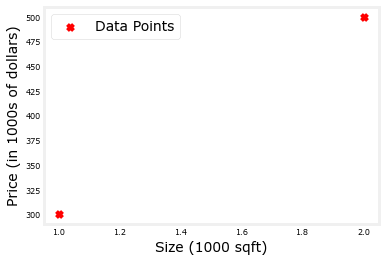

In [4]:
X_train = np.array([[1.0], [2.0]], dtype=np.float32)           #(size in 1000 square feet)
Y_train = np.array([[300.0], [500.0]], dtype=np.float32)       #(price in 1000s of dollars)

fig, ax = plt.subplots(1,1)
ax.scatter(X_train, Y_train, marker='x', c='r', label="Data Points")
ax.legend( fontsize='xx-large')
ax.set_ylabel('Price (in 1000s of dollars)', fontsize='xx-large')
ax.set_xlabel('Size (1000 sqft)', fontsize='xx-large')
plt.show()

### Regression/Linear Model 
The function implemented by a neuron with no activation is the same as in Course 1, linear regression:

一个没有激活函数的神经元所实现的功能与课程1中的线性回归相同：

$$ f_{\mathbf{w},b}(x^{(i)}) = \mathbf{w}\cdot x^{(i)} + b \tag{1}$$



We can define a layer with one neuron or unit and compare it to the familiar linear regression function.

我们可以定义一个包含一个神经元或单元的层，并将其与熟悉的线性回归函数进行比较。

In [5]:
linear_layer = tf.keras.layers.Dense(units=1, activation = 'linear', )
# torch nn.Linear   nn.Linear(20, 30)

- 密集层（Dense Layer）、全连接层（Fully Connected Layer）或线性层（Linear Layer）
- units：输出的维度大小，改变inputs的最后一维
- activation：激活函数，即神经网络的非线性变化
- https://keras.io/2.17/api/layers/core_layers/dense/
- https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense

Let's examine the weights.

让我们来检查一下权重。

In [6]:
linear_layer.get_weights()

[]

There are no weights as the weights are not yet instantiated. Let's try the model on one example in `X_train`. This will trigger the instantiation of the weights. Note, the input to the layer must be 2-D, so we'll reshape it.

目前还没有权重，因为权重尚未实例化。让我们在 `X_train` 中的一个示例上尝试这个模型。这将触发权重的实例化。请注意，输入到该层的数据必须是二维的，因此我们需要对其进行重塑(reshape)。

注意：这里的2维表示2个维度

In [7]:
X_train.shape

(2, 1)

In [8]:
X_train[0].shape

(1,)

In [9]:
a1 = linear_layer(X_train[0].reshape(1,1))
print(a1)

tf.Tensor([[1.58]], shape=(1, 1), dtype=float32)


The result is a tensor (another name for an array) with a shape of (1,1) or one entry.   
Now let's look at the weights and bias. These weights are randomly initialized to small numbers and the bias defaults to being initialized to zero.

结果是一个形状为(1,1)的张量（数组的另一种名称），即包含一个元素。

现在让我们来看看权重和偏置。这些权重被随机初始化为很小的数值，而偏置则默认初始化为零。

In [10]:
w, b= linear_layer.get_weights()
print(f"w = {w}, b={b}")

w = [[1.58]], b=[0.]


- get_weights:  Return the values of layer.weights as a list of NumPy arrays.
- https://keras.io/api/layers/base_layer/

In [11]:
linear_layer.get_weights()

[array([[1.58]], dtype=float32), array([0.], dtype=float32)]

A linear regression model (1) with a single input feature will have a single weight and bias. This matches the dimensions of our `linear_layer` above.   

The weights are initialized to random values so let's set them to some known values.

一个具有单个输入特征的线性回归模型（1）将具有一个权重和一个偏置。这与我们上面定义的 `linear_layer` 的维度相匹配。

权重被初始化为随机值，因此让我们将它们设置为一些已知的值。

In [12]:
set_w = np.array([[200]])
set_b = np.array([100])

# set_weights takes a list of numpy arrays
linear_layer.set_weights([set_w, set_b])
print(linear_layer.get_weights())

[array([[200.]], dtype=float32), array([100.], dtype=float32)]


In [13]:
X_train[0]

array([1.], dtype=float32)

Let's compare equation (1) to the layer output.

与公式1的输出进行比较（根据公式1使用np.dot计算）

In [14]:
a1 = linear_layer(X_train[0].reshape(1,1))
print(a1)
alin = np.dot(set_w,X_train[0].reshape(1,1)) + set_b
print(alin)

tf.Tensor([[300.]], shape=(1, 1), dtype=float32)
[[300.]]


They produce the same values!
Now, we can use our linear layer to make predictions on our training data.

它们产生的值是相同的！
现在，我们可以使用我们的线性层来对训练数据进行预测。

In [15]:
prediction_tf = linear_layer(X_train)
prediction_np = np.dot( X_train, set_w) + set_b

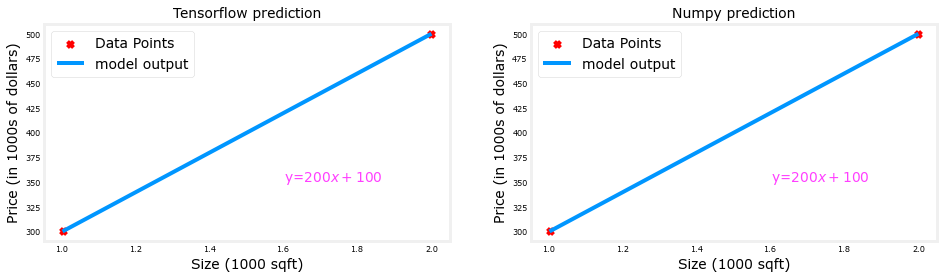

In [16]:
plt_linear(X_train, Y_train, prediction_tf, prediction_np)

## Neuron with Sigmoid activation
## 带有Sigmoid激活函数的神经元

一个带有Sigmoid激活函数的神经元/单元所实现的功能与课程1中的逻辑回归相同：

The function implemented by a neuron/unit with a sigmoid activation is the same as in Course 1, logistic  regression:

$$ f_{\mathbf{w},b}(x^{(i)}) = g(\mathbf{w}x^{(i)} + b) \tag{2}$$

where（其中） $$g(x) = sigmoid(x)$$ 

Let's set $w$ and $b$ to some known values and check the model.

让我们将 $w$ 和 $b$ 设置为一些已知的值，并检查模型。


### DataSet
We'll use an example from Course 1, logistic regression.

## 数据集

我们将使用课程1中逻辑回归的一个例子。

In [17]:
X_train = np.array([0., 1, 2, 3, 4, 5], dtype=np.float32).reshape(-1,1)  # 2-D Matrix
Y_train = np.array([0,  0, 0, 1, 1, 1], dtype=np.float32).reshape(-1,1)  # 2-D Matrix

In [18]:
X_train

array([[0.],
       [1.],
       [2.],
       [3.],
       [4.],
       [5.]], dtype=float32)

In [19]:
X_train.shape

(6, 1)

In [20]:
Y_train.shape

(6, 1)

In [21]:
pos = Y_train == 1
neg = Y_train == 0
X_train[pos]

array([3., 4., 5.], dtype=float32)

In [22]:
pos

array([[False],
       [False],
       [False],
       [ True],
       [ True],
       [ True]])

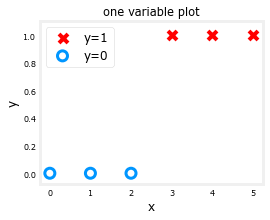

In [23]:
pos = Y_train == 1
neg = Y_train == 0

fig,ax = plt.subplots(1,1,figsize=(4,3))
ax.scatter(X_train[pos], Y_train[pos], marker='x', s=80, c = 'red', label="y=1")
ax.scatter(X_train[neg], Y_train[neg], marker='o', s=100, label="y=0", facecolors='none', 
              edgecolors=dlc["dlblue"],lw=3)

ax.set_ylim(-0.08,1.1)
ax.set_ylabel('y', fontsize=12)
ax.set_xlabel('x', fontsize=12)
ax.set_title('one variable plot')
ax.legend(fontsize=12)
plt.show()

### Logistic Neuron
We can implement a 'logistic neuron' by adding a sigmoid activation. The function of the neuron is then described by (2) above.   
This section will create a Tensorflow Model that contains our logistic layer to demonstrate an alternate method of creating models. Tensorflow is most often used to create multi-layer models. The [Sequential](https://keras.io/guides/sequential_model/) model is a convenient means of constructing these models.

## 逻辑神经元

我们可以通过添加一个Sigmoid激活函数来实现一个“逻辑神经元”。此时，神经元的函数如公式（2）所示。

本节将创建一个包含逻辑层的TensorFlow模型，以展示创建模型的另一种方法。TensorFlow通常用于创建多层模型。Sequential模型(`序贯模型`)是构建这些模型的一种便捷方式。



- https://keras.io/2.17/api/models/sequential/

- https://www.tensorflow.org/api_docs/python/tf/keras/Sequential



  类似于Torch中的nn.Sequential

- https://www.cnblogs.com/BlairGrowing/p/15427842.html

In [26]:
model = Sequential(
    [
        tf.keras.layers.Dense(1, input_dim=1,  activation = 'sigmoid', name='L1'),
        #tf.keras.layers.Dense(1, input_dim=1,  activation = 'sigmoid', name='L2'),   # 可以试试运行这行代码，添加一层，从而构建2层的神经网络，然后重新运行model.summary()
    ]
)

`model.summary()` shows the layers and number of parameters in the model. There is only one layer in this model and that layer has only one unit. The unit has two parameters, $w$ and $b$.

`model.summary()` 显示了模型中的层和参数数量。在这个模型中，只有一层，而这一层只有一个单元。这个单元有两个参数，即 $w$ 和 $b$。

` name='L1' ` 可以理解为给该层网络的起的名字

In [27]:
model.summary()

Model: "sequential_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
L1 (Dense)                   (None, 1)                 2         
Total params: 2
Trainable params: 2
Non-trainable params: 0
_________________________________________________________________


- 可以试试运行下面这行代码，添加一层，并运行model.summary()，看看有什么和之前model.summary()的输出有什么变化。

In [31]:
#model.add(tf.keras.layers.Dense(1, input_dim=1,  activation = 'sigmoid', name='L3')) 
#model.summary()

In [32]:
logistic_layer = model.get_layer('L1')
w,b = logistic_layer.get_weights()
print(w,b)
print(w.shape,b.shape)

[[2.]] [-4.5]
(1, 1) (1,)


Let's set the weight and bias to some known values.

让我们将权重和偏置设置为一些已知的值。

In [33]:
set_w = np.array([[2]])
set_b = np.array([-4.5])
# set_weights takes a list of numpy arrays
logistic_layer.set_weights([set_w, set_b])#设置网络的权重
print(logistic_layer.get_weights())

[array([[2.]], dtype=float32), array([-4.5], dtype=float32)]


Let's compare equation (2) to the layer output.

让我们将方程（2）与层的输出进行比较。

In [34]:
a1 = model.predict(X_train[0].reshape(1,1))
print(a1)
alog = sigmoidnp(np.dot(set_w,X_train[0].reshape(1,1)) + set_b)
print(alog)

[[0.01]]
[[0.01]]


They produce the same values!
Now, we can use our logistic layer and NumPy model to make predictions on our training data.

它们产生的值是相同的！
现在，我们可以使用我们的逻辑层和NumPy模型来对训练数据进行预测。

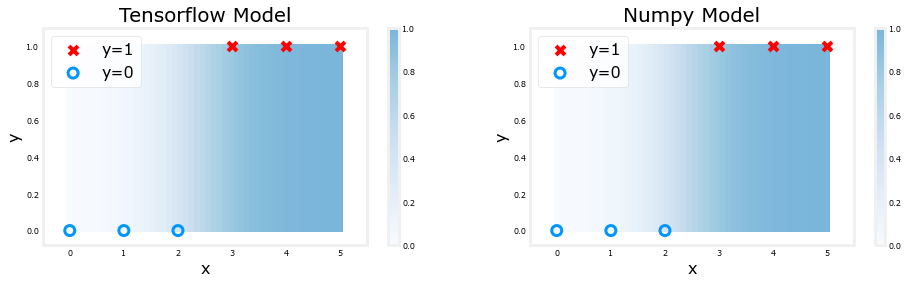

In [35]:
plt_logistic(X_train, Y_train, model, set_w, set_b, pos, neg)

The shading above reflects the output of the sigmoid which varies from 0 to 1.

上面的阴影反映了Sigmoid函数的输出，其值在0到1之间变化。

# Congratulations!
You built a very simple neural network and have explored the similarities of a neuron to the linear and logistic regression from Course 1.

# 祝贺你！

你构建了一个非常简单的神经网络，并探索了神经元与课程1中线性回归和逻辑回归的相似之处。